# Sprint 10 · Reto «¿Vale la pena la red?» · Equipo 5 Green

Fecha : 17-18.11.2026

Scrum master Cristina, Tecnico Francis

**Equipo:** Cristina, Miguel, Fran, Andri y Anzhela · **Problema elegido:** cancelaciones (`cancelada`)

**Escena del cliente.** La dirección de TurisData Canarias pregunta: *«Todo el mundo habla de redes neuronales. ¿Debemos cambiar nuestro modelo de cancelaciones por una red?»*
Respondemos con evidencias: comparamos un MLP con un modelo de boosting de árboles (misma partición, mismas métricas), medimos el coste y diagnosticamos el sobreajuste con curvas.

**Cómo repetirlo:** abrir en Google Colab (CPU, sin GPU) → *Entorno de ejecución → Reiniciar y ejecutar todo*. Los datos se descargan solos en la primera celda.

In [ ]:
# Preparación (ejecuta esta celda siempre la primera)
import os, urllib.request

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos", "../../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta


In [ ]:
import os, time
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, accuracy_score, mean_absolute_error

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)

## 1. Datos y partición (la misma para todos los modelos)
Comparar modelos con particiones distintas no es justo. Usamos **una** partición: 64 % entrenamiento, 16 % validación (decisiones y curvas) y 20 % prueba (veredicto final, una sola vez).
El escalador se ajusta **solo con el entrenamiento** (`fit_transform` en entrenamiento, `transform` en validación y prueba): así no hay fuga de datos.

In [ ]:
df = pd.read_csv(dato("reservas_turisdata.csv"), parse_dates=["fecha_llegada"])
df["mes_llegada"] = df["fecha_llegada"].dt.month
num = ["antelacion_dias", "noches", "adultos", "ninos", "peticiones_especiales", "cliente_repetidor",
       "cancelaciones_previas", "mes_llegada", "precio_noche"]
cat = ["tipo_habitacion", "regimen", "canal", "pais_origen", "tarifa", "deposito"]
X, y = df[num + cat], df["cancelada"].to_numpy()
X_res, X_pru, y_res, y_pru = train_test_split(X, y, test_size=0.2, random_state=SEMILLA, stratify=y)
X_ent, X_val, y_ent, y_val = train_test_split(X_res, y_res, test_size=0.2, random_state=SEMILLA, stratify=y_res)
pre = ColumnTransformer([("n", StandardScaler(), num), ("c", OneHotEncoder(handle_unknown="ignore"), cat)])
A_ent = pre.fit_transform(X_ent).astype("float32")
A_val = pre.transform(X_val).astype("float32")
A_pru = pre.transform(X_pru).astype("float32")
print(A_ent.shape, A_val.shape, A_pru.shape)

(3840, 35) (960, 35) (1200, 35)


In [ ]:
# Comprobación del escalado: media de las 9 columnas numéricas
print("entrenamiento:", A_ent[:, :9].mean(axis=0).round(2))
print("validación:   ", A_val[:, :9].mean(axis=0).round(2))

entrenamiento: [-0.  0.  0. -0.  0. -0. -0.  0. -0.]
validación:    [ 0.02  0.03  0.    0.02  0.01 -0.07 -0.07 -0.01 -0.03]


## 2. Una función para evaluar a todos por igual
**Ejercicio 1.** `evaluar(y_real, prob, umbral=0.5)` devuelve un diccionario con `"AUC"`, `"AP"`, `"F1"` y `"exactitud"`. AUC y AP se calculan con las probabilidades; F1 y exactitud, con las clases que salen de aplicar el umbral.

In [ ]:
def evaluar(y_real, prob, umbral=0.5):
    clases = (np.asarray(prob) >= umbral).astype(int)
    return {"AUC": roc_auc_score(y_real, prob),
            "AP": average_precision_score(y_real, prob),
            "F1": f1_score(y_real, clases),
            "exactitud": accuracy_score(y_real, clases)}

_r = evaluar(np.array([0, 0, 1, 1]), np.array([0.1, 0.6, 0.4, 0.9]))
assert set(_r) == {"AUC", "AP", "F1", "exactitud"}, "El diccionario debe tener las claves AUC, AP, F1 y exactitud"
assert abs(_r["AUC"] - 0.75) < 1e-9 and abs(_r["exactitud"] - 0.5) < 1e-9, "Revisa: AUC esperado 0.75 y exactitud 0.5 en la prueba mínima"

## 3. La referencia: boosting de árboles
Se entrena con las mismas filas y columnas ya preprocesadas que la red. Medimos también el **tiempo**: forma parte del coste. No cambiamos la referencia para que la red gane.

In [ ]:
t0 = time.time()
boost = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_depth=4, random_state=SEMILLA)
boost.fit(A_ent, y_ent)
t_boost = time.time() - t0
prob_boost_val, prob_boost_pru = boost.predict_proba(A_val)[:, 1], boost.predict_proba(A_pru)[:, 1]
print(f"Boosting entrenado en {t_boost:.1f} s · AUC validación = {roc_auc_score(y_val, prob_boost_val):.3f}")

Boosting entrenado en 1.0 s · AUC validación = 0.739


## 4. El MLP, con las buenas prácticas del Sprint 10
Pequeño, con L2, dropout y parada temprana (máximo 40 épocas). Lo entrenamos **con 3 semillas** para no depender de la suerte.

`ELEGIDA` son los ajustes de la variante que elegimos en la sección 4b **mirando solo la validación**. Elegida: **más L2 (l2=0.01)**.

In [ ]:
def construir_mlp(n_entradas, capas=(64, 32), l2=0.003, dropout=0.3, tasa=1e-3):
    m = keras.Sequential([keras.layers.Input(shape=(n_entradas,))])
    for u in capas:
        m.add(keras.layers.Dense(u, activation="relu", kernel_regularizer=keras.regularizers.l2(l2)))
        m.add(keras.layers.Dropout(dropout))
    m.add(keras.layers.Dense(1, activation="sigmoid"))
    m.compile(optimizer=keras.optimizers.Adam(tasa), loss="binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
    return m

ELEGIDA = {"l2": 0.01}   # ajustes de la variante elegida (con {} se usa la base)

modelos_mlp, historiales, tiempos = [], [], []
for semilla in (1, 2, 3):
    keras.utils.set_random_seed(semilla)
    t0 = time.time()
    m = construir_mlp(A_ent.shape[1], **ELEGIDA)
    h = m.fit(A_ent, y_ent, validation_data=(A_val, y_val), epochs=40, batch_size=64, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)])
    tiempos.append(time.time() - t0)
    modelos_mlp.append(m); historiales.append(h)
    print(f"semilla {semilla}: {len(h.history['loss'])} épocas, AUC validación = {max(h.history['val_auc']):.3f} (máx.)")

semilla 1: 36 épocas, AUC validación = 0.749 (máx.)
semilla 2: 28 épocas, AUC validación = 0.750 (máx.)
semilla 3: 32 épocas, AUC validación = 0.748 (máx.)


**Ejercicio 2.** `aucs_mlp_val`: AUC de cada modelo de `modelos_mlp` sobre la **validación**; `auc_mlp_medio`: su media.

In [ ]:
aucs_mlp_val = [roc_auc_score(y_val, m.predict(A_val, verbose=0).ravel()) for m in modelos_mlp]
auc_mlp_medio = float(np.mean(aucs_mlp_val))

assert len(aucs_mlp_val) == 3, "Debe haber un AUC por cada uno de los 3 modelos"
assert 0.6 < auc_mlp_medio < 0.85, "El AUC medio debería rondar 0.7–0.75"
print("AUC de validación por semilla:", np.round(aucs_mlp_val, 3), "· media", round(auc_mlp_medio, 3))
print(f"AUC de validación del MLP: {np.mean(aucs_mlp_val):.3f} ± {np.std(aucs_mlp_val):.3f}")

AUC de validación por semilla: [0.749 0.749 0.748] · media 0.748
AUC de validación del MLP: 0.748 ± 0.001


### 4b. Variantes del MLP (solo validación, un ajuste cada vez)
Base y tres variantes, siempre con las mismas 3 semillas. Los resultados se guardan en listas nuevas para no pisar `modelos_mlp` ni `historiales`. **La prueba no se toca.** Con más L2 la pérdida sube aunque la red no sea peor: entre variantes se compara sobre todo el AUC de validación.

In [ ]:
variantes = {
    "base": dict(capas=(64, 32), l2=0.003, dropout=0.3, tasa=1e-3),
    "menos neuronas: capas=(32,)": dict(capas=(32,), l2=0.003, dropout=0.3, tasa=1e-3),
    "más dropout: 0.5": dict(capas=(64, 32), l2=0.003, dropout=0.5, tasa=1e-3),
    "más L2: 0.01": dict(capas=(64, 32), l2=0.01, dropout=0.3, tasa=1e-3),
}
filas = []
for etiqueta, ajustes in variantes.items():
    perd_ent_v, perd_val_v, aucs_v = [], [], []
    for semilla in (1, 2, 3):
        keras.utils.set_random_seed(semilla)
        m = construir_mlp(A_ent.shape[1], **ajustes)
        h = m.fit(A_ent, y_ent, validation_data=(A_val, y_val), epochs=40, batch_size=64, verbose=0,
                  callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)])
        mejor = int(np.argmin(h.history["val_loss"]))
        perd_ent_v.append(h.history["loss"][mejor]); perd_val_v.append(h.history["val_loss"][mejor])
        aucs_v.append(roc_auc_score(y_val, m.predict(A_val, verbose=0).ravel()))
    filas.append({"Variante": etiqueta, "Error entrenamiento": np.mean(perd_ent_v), "Error validación": np.mean(perd_val_v),
                  "AUC validación (media)": np.mean(aucs_v), "± desviación": np.std(aucs_v)})
tabla_variantes = pd.DataFrame(filas).set_index("Variante")
tabla_variantes.round(3)

,Error entrenamiento,Error validación,AUC validación (media),± desviación
Variante,,,,
base,0.591,0.618,0.744,0.002
"menos neuronas: capas=(32,)",0.579,0.605,0.746,0.001
más dropout: 0.5,0.597,0.614,0.746,0.002
más L2: 0.01,0.606,0.614,0.748,0.001


**Lectura de la tabla de variantes** (AUC de validación, media de 3 semillas):
- **Base** (64, 32 · dropout 0.3 · L2 0.003): 0.744 ± 0.001. Es nuestra regla de medir.
- **Menos neuronas** `capas=(32,)`: 0.746, mejora de 0.002 (≈ ruido entre semillas).
- **Más dropout** 0.5: 0.746, mejora de 0.002 (≈ ruido).
- **Más L2** 0.01: **0.748 ± 0.001**, mejora de 0.004, mayor que el ± de las semillas. La pérdida sube un poco porque incluye el castigo L2, no porque la red sea peor.

**Elegimos `l2=0.01`** por tener el mayor AUC de validación. Aun así, las cuatro variantes están dentro de 0.004 de AUC: ninguna cambia la historia. La prueba no se ha mirado para decidir.

## 5. Diagnóstico con curvas de aprendizaje
Con `EarlyStopping` la red se detiene a tiempo; aun así miramos las curvas: ¿cuántas épocas útiles? ¿cuánta brecha entre entrenamiento y validación? (El eje horizontal empieza en 0: la primera época es el 0 del dibujo.)

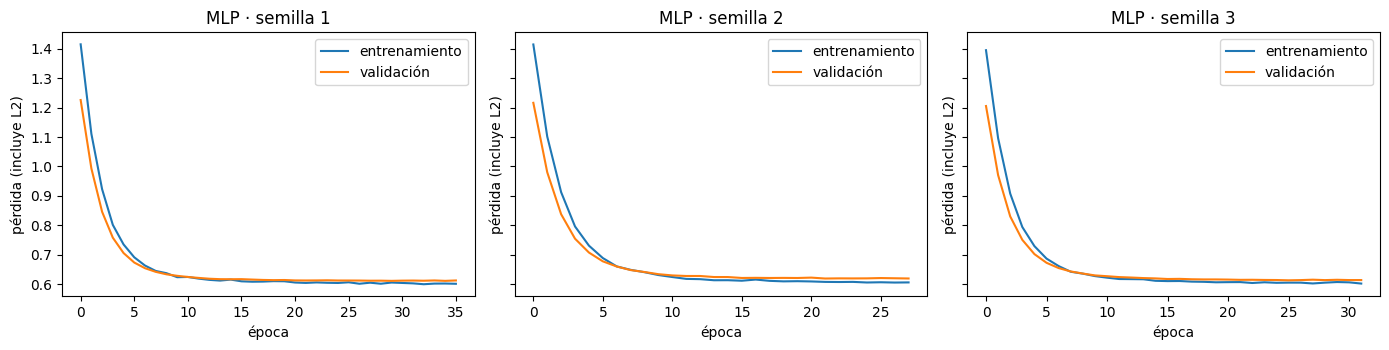

semilla 1: la pérdida de validación es mínima en la época 30 de 36
semilla 2: la pérdida de validación es mínima en la época 22 de 28
semilla 3: la pérdida de validación es mínima en la época 26 de 32


In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for eje, h, s in zip(ejes, historiales, (1, 2, 3)):
    eje.plot(h.history["loss"], label="entrenamiento"); eje.plot(h.history["val_loss"], label="validación")
    eje.set_title(f"MLP · semilla {s}"); eje.set_xlabel("época"); eje.set_ylabel("pérdida (incluye L2)"); eje.legend()
plt.tight_layout()
plt.savefig("curvas_aprendizaje.png", dpi=120)   # imagen opcional para el informe
plt.show()

for s, h in zip((1, 2, 3), historiales):
    print(f"semilla {s}: la pérdida de validación es mínima en la época {int(np.argmin(h.history['val_loss'])) + 1} de {len(h.history['val_loss'])}")

**Ejercicio 3.** `diagnostico(historial, margen=0.03)` devuelve `"sobreajuste"` si la pérdida de validación **final** supera a su **mínimo** en más de `margen` **o** si la validación final supera a la de entrenamiento en más de `0.15`; si no, `"sin sobreajuste claro"`.

In [ ]:
def diagnostico(historial, margen=0.03):
    pv, pe = historial.history["val_loss"], historial.history["loss"]
    if pv[-1] > min(pv) + margen or (pv[-1] - pe[-1]) > 0.15:
        return "sobreajuste"
    return "sin sobreajuste claro"

class _H:  # historial de juguete para probar la función
    def __init__(self, loss, val): self.history = {"loss": loss, "val_loss": val}
assert diagnostico(_H([0.6, 0.3, 0.1], [0.6, 0.65, 0.9])) == "sobreajuste", "Validación creciente y brecha grande = sobreajuste"
assert diagnostico(_H([0.7, 0.65, 0.62], [0.7, 0.66, 0.64])) == "sin sobreajuste claro", "Curvas paralelas y juntas: sin sobreajuste"
for s, h in zip((1, 2, 3), historiales):
    print(f"MLP semilla {s}:", diagnostico(h))

MLP semilla 1: sin sobreajuste claro
MLP semilla 2: sin sobreajuste claro
MLP semilla 3: sin sobreajuste claro


### Nuestro diagnóstico (frase para el informe)
Con la variante `l2=0.01`, la pérdida de validación deja de mejorar entre las épocas 22 y 30 (según la semilla) y el entrenamiento sigue bajando muy poco; la brecha final entre validación y entrenamiento es de solo ≈ 0.01 (0.615 frente a 0.606 en el mejor punto). **No hay sobreajuste claro: las dos curvas bajan juntas y la parada temprana corta a tiempo.**

## 6. El veredicto en el conjunto de prueba
Ahora sí se usa la prueba: **una sola vez**, con el MLP elegido y con la referencia. Para el MLP tomamos la **media de las 3 semillas** de la probabilidad (un pequeño *ensemble*). No se cambia nada después de ver esta tabla.

In [ ]:
prob_mlp_pru = np.mean([m.predict(A_pru, verbose=0).ravel() for m in modelos_mlp], axis=0)
tabla = pd.DataFrame({"Boosting de árboles": evaluar(y_pru, prob_boost_pru),
                      "MLP (media de 3 semillas)": evaluar(y_pru, prob_mlp_pru)}).T
tabla["entrenamiento (s)"] = [t_boost, np.mean(tiempos)]
tabla["parámetros / árboles"] = ["200 iteraciones × árboles de profundidad ≤ 4", f"{modelos_mlp[0].count_params():,}".replace(",", ".") + " pesos"]
tabla.round(3)

,AUC,AP,F1,exactitud,entrenamiento (s),parámetros / árboles
Boosting de árboles,0.738,0.721,0.639,0.672,0.998,200 iteraciones × árboles de profundidad ≤ 4
MLP (media de 3 semillas),0.745,0.725,0.617,0.672,14.233,4.417 pesos


### ¿La diferencia es real o es ruido?
Estimamos la incertidumbre de la **diferencia de AUC** remuestreando la prueba (bootstrap, 300 repeticiones). Si el intervalo incluye el 0, no podemos afirmar que un modelo sea mejor.

Diferencia de AUC (MLP − boosting): +0.007 · intervalo 95 %: [-0.004, +0.020]


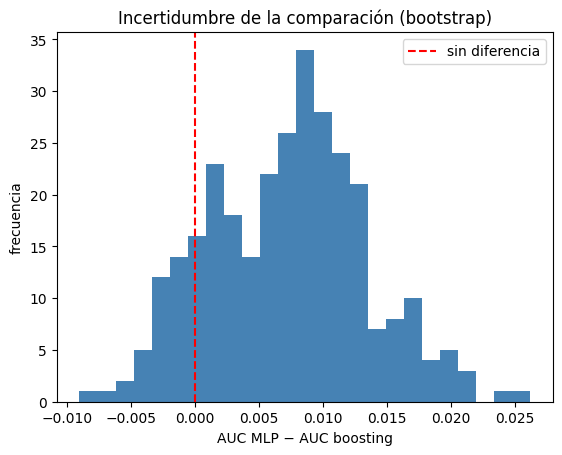

In [ ]:
rng = np.random.default_rng(SEMILLA)
difs = []
for _ in range(300):
    idx = rng.integers(0, len(y_pru), len(y_pru))
    if len(np.unique(y_pru[idx])) < 2:
        continue
    difs.append(roc_auc_score(y_pru[idx], prob_mlp_pru[idx]) - roc_auc_score(y_pru[idx], prob_boost_pru[idx]))
inf, sup = np.percentile(difs, [2.5, 97.5])
print(f"Diferencia de AUC (MLP − boosting): {np.mean(difs):+.3f} · intervalo 95 %: [{inf:+.3f}, {sup:+.3f}]")
plt.hist(difs, bins=25, color="steelblue"); plt.axvline(0, color="red", ls="--", label="sin diferencia")
plt.xlabel("AUC MLP − AUC boosting"); plt.ylabel("frecuencia"); plt.title("Incertidumbre de la comparación (bootstrap)")
plt.legend(); plt.show()

**Ejercicio 4.** `hay_diferencia` es `True` si el intervalo `[inf, sup]` **no** contiene el 0; `mejor_modelo` es `"MLP"`, `"Boosting"` o `"Empate"`.

In [ ]:
hay_diferencia = bool(inf > 0 or sup < 0)
mejor_modelo = ("MLP" if np.mean(difs) > 0 else "Boosting") if hay_diferencia else "Empate"

assert isinstance(hay_diferencia, bool), "hay_diferencia debe ser True/False"
assert mejor_modelo in ("MLP", "Boosting", "Empate"), "mejor_modelo debe ser 'MLP', 'Boosting' o 'Empate'"
assert (mejor_modelo == "Empate") == (not hay_diferencia), "Si no hay diferencia clara debe ser 'Empate' (y viceversa)"
print("Veredicto estadístico:", mejor_modelo)

Veredicto estadístico: Empate


### Coste: tiempo, complejidad y explicabilidad

In [ ]:
t_mlp = float(np.mean(tiempos))
print(f"Tiempo de entrenamiento: boosting {t_boost:.1f} s · MLP {t_mlp:.1f} s por semilla → el MLP tarda ≈ {t_mlp / t_boost:.0f} veces más")
print(f"Complejidad: boosting = 200 iteraciones de árboles (profundidad ≤ 4) · MLP = {modelos_mlp[0].count_params():,} pesos".replace(",", "."))
print("Explicabilidad: el boosting se explica con la importancia de variables y árboles; el MLP es una caja negra de pesos (más difícil de justificar a un directivo).")

Tiempo de entrenamiento: boosting 1.0 s · MLP 14.2 s por semilla → el MLP tarda ≈ 14 veces más
Complejidad: boosting = 200 iteraciones de árboles (profundidad ≤ 4) · MLP = 4.417 pesos
Explicabilidad: el boosting se explica con la importancia de variables y árboles; el MLP es una caja negra de pesos (más difícil de justificar a un directivo).


## 7. Extras
### 7.1 IA responsable: medir el efecto por país y canal (solo validación)
Riesgo: el modelo puede rendir peor con países o canales poco frecuentes. Medimos el AUC de la red elegida por grupo **en validación** (la prueba no se toca).

In [ ]:
prob_mlp_val = np.mean([m.predict(A_val, verbose=0).ravel() for m in modelos_mlp], axis=0)
def auc_por_grupo(col, minimo=40):
    filas = []
    for g, idx in X_val.reset_index(drop=True).groupby(col).groups.items():
        idx = list(idx)
        if len(idx) >= minimo and len(np.unique(y_val[idx])) == 2:
            filas.append({col: g, "reservas": len(idx), "AUC MLP": roc_auc_score(y_val[idx], prob_mlp_val[idx]),
                          "AUC boosting": roc_auc_score(y_val[idx], prob_boost_val[idx])})
    return pd.DataFrame(filas).set_index(col).round(3)
display(auc_por_grupo("pais_origen"))
display(auc_por_grupo("canal"))

,reservas,AUC MLP,AUC boosting
pais_origen,,,
DE,142,0.701,0.691
ES,250,0.753,0.762
NL,53,0.895,0.895
Nordicos,84,0.819,0.777
UK,237,0.758,0.732
otros,103,0.643,0.644


,reservas,AUC MLP,AUC boosting
canal,,,
agencia,190,0.743,0.720
directo,234,0.712,0.727
empresa,62,0.775,0.780
web_intermediaria,474,0.732,0.716


### 7.2 IA responsable: el umbral y el coste de equivocarse (solo validación)
Cancelar «de más» (marcar como cancelación una reserva que sí llega) provoca *overbooking*; «de menos» deja habitaciones vacías. Veamos cómo cambian F1 y exactitud con el umbral en la validación.

In [ ]:
filas = []
for u in (0.3, 0.4, 0.5, 0.6, 0.7):
    r = evaluar(y_val, prob_mlp_val, umbral=u)
    clases = (prob_mlp_val >= u).astype(int)
    filas.append({"umbral": u, "F1": r["F1"], "exactitud": r["exactitud"],
                  "falsas alarmas (predice cancela y llega)": int(((clases == 1) & (y_val == 0)).sum()),
                  "cancelaciones no detectadas": int(((clases == 0) & (y_val == 1)).sum())})
pd.DataFrame(filas).set_index("umbral").round(3)

,F1,exactitud,falsas alarmas (predice cancela y llega),cancelaciones no detectadas
umbral,,,,
0.3,0.687,0.630,303,52
0.4,0.691,0.682,205,100
0.5,0.631,0.686,117,184
0.6,0.504,0.650,66,270
0.7,0.351,0.619,24,342


### 7.3 Variante de regresión (precio por noche)
El mismo razonamiento para `precio_noche`. Se quita `precio_noche` de las entradas.

In [ ]:
num_r = [c for c in num if c != "precio_noche"]
Xr = df[num_r + cat]; yr = df["precio_noche"].to_numpy()
Xr_res, Xr_pru, yr_res, yr_pru = train_test_split(Xr, yr, test_size=0.2, random_state=SEMILLA)
pre_r = ColumnTransformer([("n", StandardScaler(), num_r), ("c", OneHotEncoder(handle_unknown="ignore"), cat)])
Ar_res = pre_r.fit_transform(Xr_res).astype("float32"); Ar_pru = pre_r.transform(Xr_pru).astype("float32")
mu, sd = yr_res.mean(), yr_res.std()

boost_r = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_depth=4, random_state=SEMILLA).fit(Ar_res, yr_res)
ridge_r = Ridge().fit(Ar_res, yr_res)
keras.utils.set_random_seed(SEMILLA)
mlp_r = keras.Sequential([keras.layers.Input(shape=(Ar_res.shape[1],)), keras.layers.Dense(32, activation="relu"),
                          keras.layers.Dense(16, activation="relu"), keras.layers.Dense(1)])
mlp_r.compile("adam", "mse")
mlp_r.fit(Ar_res, ((yr_res - mu) / sd).astype("float32"), validation_split=0.2, epochs=40, batch_size=64, verbose=0,
          callbacks=[keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True)])
pd.DataFrame({"MAE (€)": {
    "Boosting": mean_absolute_error(yr_pru, boost_r.predict(Ar_pru)),
    "Ridge (lineal)": mean_absolute_error(yr_pru, ridge_r.predict(Ar_pru)),
    "MLP": mean_absolute_error(yr_pru, mlp_r.predict(Ar_pru, verbose=0).ravel() * sd + mu)}}).round(2)

,MAE (€)
Boosting,6.92
Ridge (lineal),11.87
MLP,11.91


### 7.4 Guardar el MLP elegido y probarlo recargado
Guardamos la primera semilla y comprobamos que, al recargarla, da las mismas probabilidades (se evalúa sobre validación, no sobre la prueba).

In [ ]:
modelos_mlp[0].save("mlp_final.keras")
recargado = keras.models.load_model("mlp_final.keras")
p1 = modelos_mlp[0].predict(A_val, verbose=0).ravel()
p2 = recargado.predict(A_val, verbose=0).ravel()
print("Máxima diferencia entre el modelo original y el recargado:", float(np.abs(p1 - p2).max()))
assert np.allclose(p1, p2, atol=1e-6), "El modelo recargado debería dar las mismas probabilidades"
print("AUC validación (recargado):", round(roc_auc_score(y_val, p2), 3))

Máxima diferencia entre el modelo original y el recargado: 0.0
AUC validación (recargado): 0.749


### 7.5 Versiones usadas (para el README)

In [ ]:
import sys, sklearn, tensorflow as tf
print("Python", sys.version.split()[0], "· Keras", keras.__version__, "· TensorFlow", tf.__version__,
      "· scikit-learn", sklearn.__version__, "· pandas", pd.__version__, "· numpy", np.__version__)
print("Semillas: partición y boosting =", SEMILLA, "· MLP = 1, 2, 3 · bootstrap =", SEMILLA)

Python 3.13.18 · Keras 3.13.2 · TensorFlow 2.21.0 · scikit-learn 1.6.1 · pandas 2.2.3 · numpy 2.4.6
Semillas: partición y boosting = 42 · MLP = 1, 2, 3 · bootstrap = 42


## 8. Preguntas de reflexión
1. **Si la red y el boosting empatan, ¿cuál recomendaríamos a un hotel con un solo técnico?** El boosting: entrena en décimas de segundo, es más fácil de mantener y de explicar.
2. **¿En qué datos ganaría la red claramente?** En imágenes, texto o series temporales largas, donde hay estructura que los árboles no captan; aquí los datos son tabulares y pequeños (6000 filas).
3. **¿Qué coste tiene equivocarse?** Cancelar «de más» provoca *overbooking* (compensaciones, mala reputación); «de menos» deja habitaciones vacías. Si el overbooking cuesta más, conviene un umbral más alto (más precisión, menos falsas alarmas); ver la tabla 7.2.